<a href="https://colab.research.google.com/github/noar1997/20-Newsgroups-Text-Classification/blob/main/20261025_aron_delcid_9219670_DLBAIPNLP01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
# Dataset and data splitting
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split

# Feature extraction
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

# Machine learning models
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    precision_score,
    recall_score,
    confusion_matrix
)

# Text preprocessing
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
lemmatizer = WordNetLemmatizer()


# Data manipulation
import pandas as pd


# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Utilities
import time
from sklearn.base import clone

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
stop_words = set(stopwords.words("english"))

print("All libraries imported successfully!")

All libraries imported successfully!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [10]:
#Loading the dataset
#Removal of innecesary metadata performed as the data set is uploaded
train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))



In [11]:
#Pre processing text

def pre_process_text(text):
  lowered = text.lower()
  tokenized_lower = word_tokenize(lowered)

  tokens_no_punct = [
      token for token in tokenized_lower
      if token.isalpha()
  ]

  tokens_no_stopwords = [
      token for token in tokens_no_punct
      if token not in stop_words
  ]

  lemmatized_tokens = [
      lemmatizer.lemmatize(token)
      for token in tokens_no_stopwords
  ]

  cleaned_text = " ".join(lemmatized_tokens)
  return cleaned_text





def model_evaluation(model, X_train, y_train, X_test, y_test): #this function will be used to evaluate models, letting us decide which "model" to use for later
  start_time = time.perf_counter()
  model.fit(X_train, y_train)
  training_time = time.perf_counter() - start_time
  prediction = model.predict(X_test)

  #The following metrics are what will be used to evaluate a model

  accuracy = accuracy_score(y_test, prediction)

  precision = precision_score(y_test, prediction, average="macro")
  recall = recall_score(y_test, prediction, average="macro")

  macro_f1 = f1_score(y_test, prediction, average="macro")

  return {
        "Model": type(model).__name__,
        "Accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "Macro F1": macro_f1,
        "Training time (s): ": training_time
    }

#confussion matrix
def plot_confusion_matrix(y_test, prediction, target_names):

    cm = confusion_matrix(y_test, prediction)

    plt.figure(figsize=(14, 10))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_names,
        yticklabels=target_names
    )

    plt.title("Confusion Matrix")
    plt.xlabel("Predicted Category")
    plt.ylabel("Actual Category")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

#In order to evaluate different training sizes (10, 30, 50 and 100 percent)


def percentaged_model(model, X_train, y_train, X_test, y_test,
                      percentages=[0.10, 0.30, 0.50, 1.0]):
  results = []

  for percentage in percentages:
    #An error was encountered here whenever the model when to 100%
    #and If was used to fix it
    if percentage < 1.0:
      X_subset, _, y_subset, _ = train_test_split(
          X_train,
          y_train,
          train_size=percentage,
          random_state=42,
          stratify=y_train
      )
    else:
        #In case of the set being 100%
        X_subset = X_train
        y_subset = y_train


    copy_model = clone(model)
    copy_model.fit(X_subset, y_subset)
    prediction = copy_model.predict(X_test)


    #results storage
    results.append({
            "subset size (%)": percentage * 100,
            "documents": X_subset.shape[0],
            "accuracy": accuracy_score(y_test, prediction),
            "recall": recall_score(y_test, prediction, average="macro"),
            "precision": precision_score(y_test, prediction, average="macro"),
            "macro F1": f1_score(
                y_test, prediction, average="macro"
            )
        })
  return pd.DataFrame(results)

def model_comparison(models, X_train, y_train, X_test, y_test):
  results = []

  for name, model in models.items():
    result = model_evaluation(
        model, X_train, y_train, X_test, y_test
    )
    result["Model"]=name
    results.append(result)

  return pd.DataFrame(results)


def topic_prediction(text, model, vectorizer, target_names):
  cleaned_text = pre_process_text(text)
  text_vectorized = vectorizer.transform([cleaned_text])

  prediction = model.predict(text_vectorized)[0]
  return target_names[prediction]






In [12]:
#20 news week data set exploration
#A first exploration to determine number of documents, if any was empty,
#number of categories and documents per category was done

print("* " * 60)
print("Data set exploration")
print("* " * 60)
print("")
print("")


print("Number of training documents: ", len(train.data))
print("Number of testing documents: ", len(test.data))

print("Document categories")
print("")
category = pd.Series(train.target).value_counts().sort_index()
for i, categories  in enumerate(train.target_names):
  print(categories, ":", category.get(i, 0), "documents")
print()
print()
print("Example")
for i in range(3):
  print("Category: ", train.target_names[train.target[i]])
  print(train.data[i][:300]) #examples to determine if the removal of headers, footers and quotes

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
Data set exploration
* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 


Number of training documents:  11314
Number of testing documents:  7532
Document categories

alt.atheism : 480 documents
comp.graphics : 584 documents
comp.os.ms-windows.misc : 591 documents
comp.sys.ibm.pc.hardware : 590 documents
comp.sys.mac.hardware : 578 documents
comp.windows.x : 593 documents
misc.forsale : 585 documents
rec.autos : 594 documents
rec.motorcycles : 598 documents
rec.sport.baseball : 597 documents
rec.sport.hockey : 600 documents
sci.crypt : 595 documents
sci.electronics : 591 documents
sci.med : 594 documents
sci.space : 593 documents
soc.religion.christian : 599 documents
talk.politics.guns : 546 documents
talk.politics.mideast : 564 documents
talk.politics.misc : 465 documents
talk.religion.misc : 377

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
Experiment No 1
* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 


           Model  Accuracy  precision  recall  Macro F1  Training time (s): 
0  MultinomialNB    0.6356     0.6518    0.62    0.6046               0.0648


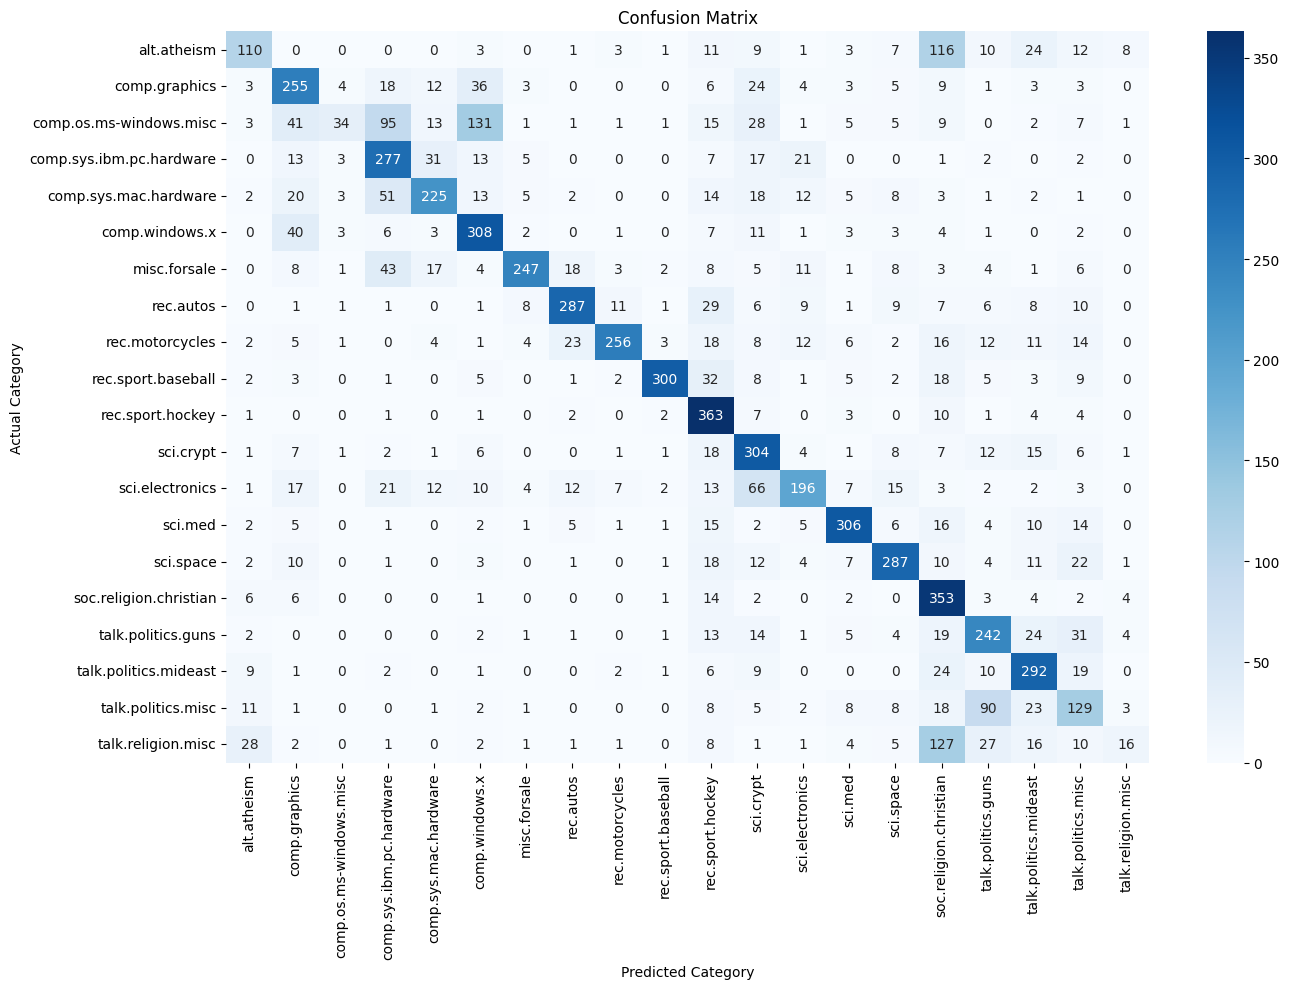

In [5]:
#Experiment No.1: A baseline Naive Bayes classifier
#a first pre processing of text, calling the function created before with a loop through all the data in train and test subsets
processed_train= [pre_process_text(text) for text in train.data]
processed_test = [pre_process_text(text) for text in test.data]

#label definition
y_train = train.target
y_test = test.target

#features will be extracted for MNB using CountVectorizer
vectorizer = CountVectorizer()
X_train = vectorizer.fit_transform(processed_train)
X_test = vectorizer.transform(processed_test)
#important to note the testing data does not use transform, as to not influence the training of the model


#Calling the Multinomial NB as the "model"
model = MultinomialNB()
results = model_evaluation(
    model, X_train, y_train, X_test, y_test
)


print("* " * 60)
print("Experiment No 1")
print("* " * 60)
print("")
print("")

print(pd.DataFrame([results]).round(4))

#Confussion matrix
predictions = model.predict(X_test)

plot_confusion_matrix(y_test, predictions, train.target_names)






* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
Experiment 2: Using smaller percentages of the data set
* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 


 subset size (%)  documents  accuracy  recall  precision  macro F1
            10.0       1131     0.415   0.402      0.552     0.369
            30.0       3394     0.540   0.524      0.617     0.506
            50.0       5657     0.576   0.560      0.636     0.541
           100.0      11314     0.636   0.620      0.652     0.605


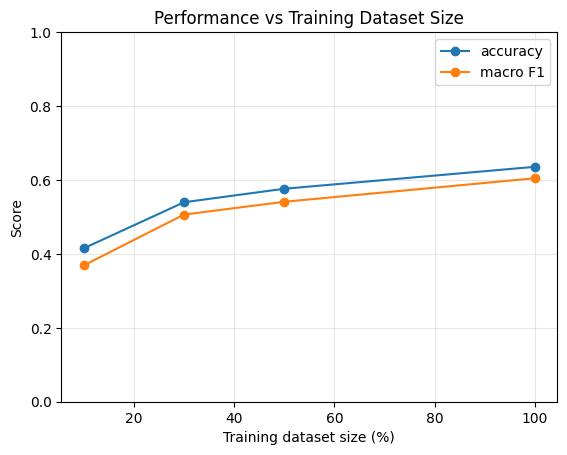

In [6]:
#For experiment No2, the aim of the test is to see the results of breaking the dataset
#into smaller parts, and check how this affects the overall model

print("* " * 60)
print("Experiment 2: Using smaller percentages of the data set")
print("* " * 60)
print("")
print("")

size_results = percentaged_model(
    MultinomialNB(), X_train, y_train, X_test, y_test
)

print(size_results.round(3).to_string(index=False))


#a visual representation of the results
size_results.plot(
    x="subset size (%)",
    y=["accuracy", "macro F1"],
    marker="o"
)

plt.title("Performance vs Training Dataset Size")
plt.xlabel("Training dataset size (%)")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.show()

In [7]:
# EXperiment No3

print("* " * 60)
print("Experiment 3: Model comparison and selection of best performing one")
print("* " * 60)
print("")
print("")

tfidef_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidef_vectorizer.fit_transform(processed_train)
X_test_tfidf = tfidef_vectorizer.transform(processed_test)

models = {
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(random_state=42),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    )
}

comparison_results = model_comparison(
    models,
    X_train_tfidf,
    y_train,
    X_test_tfidf,
    y_test
)

print("Test Results:")
print(comparison_results.round(3).to_string(index=False))

best_model_selection=(
    comparison_results.sort_values("Macro F1", ascending=False).iloc[0]["Model"])

print("Selected model:", best_model_selection)


# fitting an instance of the best selected model
print("*" * 60)
best_model = clone(models[best_model_selection])
best_model.fit(X_train_tfidf, y_train)

#Evaluation of the best selected model
test_predictions = best_model.predict(X_test_tfidf)

print("\nFinal Test Results:")
print("Selected model:", best_model_selection)
print(f"Accuracy: {accuracy_score(y_test, test_predictions):.4f}")
print(f"Precision:{precision_score(y_test, test_predictions, average='macro'):.4f} ,")
print(f"Recall: {recall_score(y_test, test_predictions, average='macro'):.4f}")
print(f"Macro F1: "f"{f1_score(y_test, test_predictions, average='macro'):.4f}")
print("*"* 60)
print("*" * 60)
print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=train.target_names,
    zero_division=0
))

print("*" * 60)


* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
Experiment 3: Model comparison and selection of best performing one
* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 


Test Results:
              Model  Accuracy  precision  recall  Macro F1  Training time (s): 
        Naive Bayes     0.658      0.715   0.637     0.626                0.040
         Linear SVM     0.680      0.676   0.668     0.669                0.958
Logistic Regression     0.673      0.675   0.660     0.660               18.396
Selected model: Linear SVM
************************************************************

Final Test Results:
Selected model: Linear SVM
Accuracy: 0.6796
Precision:0.6758 ,
Recall: 0.6683
Macro F1: 0.6687
************************************************************
************************************************************

Classification Report:
    

In [8]:
#Manual cross genre evaluation of data examples
print("* " * 60)
print("Experiment 4: Cross evaluation of data examples")
print("* " * 60)
print("")
print("")

examples_random = [
        # News  text
    {
        "topic": "News",
        "text": "NASA scientists reported new observations of a distant planet and its atmosphere.",
        "label": "sci.space"
    },
    {
        "topic": "News",
        "text": "The computer company announced a new processor designed to improve system performance.",
        "label": "comp.sys.ibm.pc.hardware"
    },

    # Academic  text
    {
        "topic": "Academic",
        "text": "This study investigates algorithms for image processing and computer vision.",
        "label": "comp.graphics"
    },
    {
        "topic": "Academic",
        "text": "Researchers analyze encryption protocols and methods for secure digital communication.",
        "label": "sci.crypt"
    },

    # Social-media text
    {
        "topic": "Social Media",
        "text": "My computer keeps crashing after the latest hardware upgrade. Any suggestions?",
        "label": "comp.sys.ibm.pc.hardware"
    },
    {
        "topic": "Social Media",
        "text": "Just watched a fascinating documentary about space exploration and distant galaxies!",
        "label": "sci.space"
    }
]

# Manual cross-genre evaluation

# Preprocess the manually written examples
examples_text = [
    pre_process_text(item["text"])
    for item in examples_random
]

# Convert the actual topic labels to numeric labels
examples_topic = [
    train.target_names.index(item["label"])
    for item in examples_random
]

# Use the TF-IDF vectorizer fitted on the training corpus
X_random = tfidef_vectorizer.transform(examples_text)

# Select the best model based on macro-F1
best_model_selection = (
    comparison_results
    .sort_values("Macro F1", ascending=False)
    .iloc[0]["Model"]
)


# Predict topics
example_predictions = best_model.predict(X_random)

print("*" * 60)

# Display results
for item, actual, predicted in zip(
    examples_random, examples_topic, example_predictions
):
    print(f"Text topic: {item['topic']}")
    print(f"Expected topic: {train.target_names[actual]}")
    print(f"Predicted topic: {train.target_names[predicted]}")
    print(f"Correct: {actual == predicted}")
    print("-" * 120)



* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
Experiment 4: Cross evaluation of data examples
* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 


************************************************************
Text topic: News
Expected topic: sci.space
Predicted topic: sci.space
Correct: True
------------------------------------------------------------------------------------------------------------------------
Text topic: News
Expected topic: comp.sys.ibm.pc.hardware
Predicted topic: comp.sys.ibm.pc.hardware
Correct: True
------------------------------------------------------------------------------------------------------------------------
Text topic: Academic
Expected topic: comp.graphics
Predicted topic: comp.graphics
Correct: True
---------------------------------------------------------------------------------------------------------------